# Continuous Optimization in Data Science: Assignment 3

**Group 3**

**Group members:**
- Simon Carlén
- Alvin Stallgård

## Q1.1 E-step: majorizer of the NLL

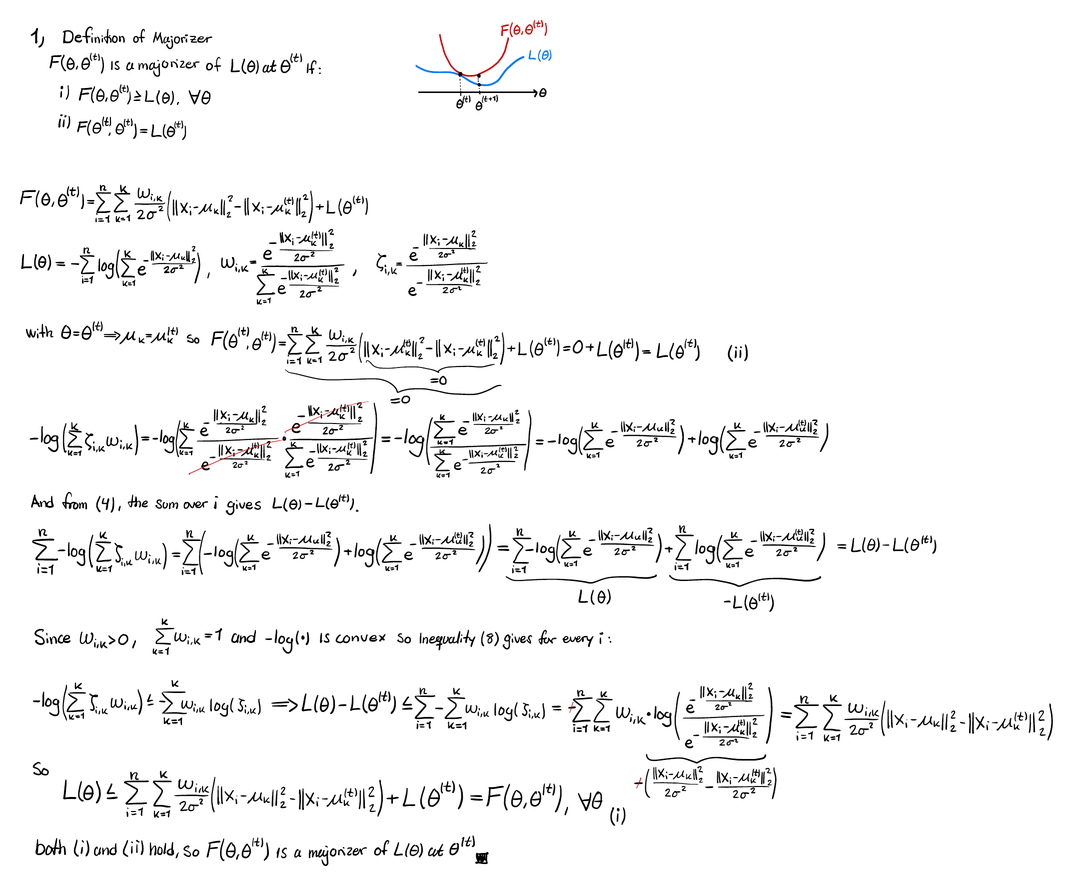

## Q1.2 M-step: centroid update

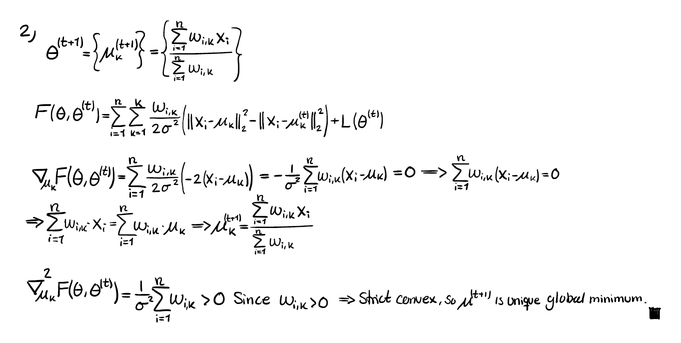

## Q1.3 EM clustering of credit card data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('CC GENERAL.csv').drop(columns='CUST_ID').dropna()
X = df.to_numpy()
X = (X - X.mean(axis=0)) / X.std(axis=0)
print(X.shape)

(8636, 17)


In [3]:
def EM_clustering(X, sigma, K):
    # Number of iterations
    iter_num = 10
    # d is the number of features and n is the number of the data points:
    (n, d) = X.shape
    # Initialize the K centroids randomly. Each row is a centroid.
    M = np.random.randn(K, d)
    # A vector that stores the NLL value in different iterations:
    value = np.zeros(iter_num)

    #start the EM loop:
    for t in range(iter_num):
        # Apply the E stape by calculating the omega_{i,k} coefficients
        omega_ = np.zeros((n, K))
        for i in range(n):
            for k in range(K):
                omega_[i, k] = -np.sum((X[i] - M[k])**2) / (2 * sigma**2)
            omega_[i, :] = np.exp(omega_[i, :] - np.max(omega_[i, :]))
            omega_[i, :] = omega_[i, :] / np.sum(omega_[i, :])

        # Apply the M step and obtain an update of M
        for k in range(K):
            M[k] = (omega_[:, k] @ X) / np.sum(omega_[:, k])

        # Calculate the NLL vale
        for i in range(n):
            a = np.zeros(K)
            for k in range(K):
                a[k] = -np.sum((X[i] - M[k])**2) / (2 * sigma**2)
            a_max = np.max(a)
            value[t] -= a_max + np.log(np.sum(np.exp(a - a_max)))

    return M, value

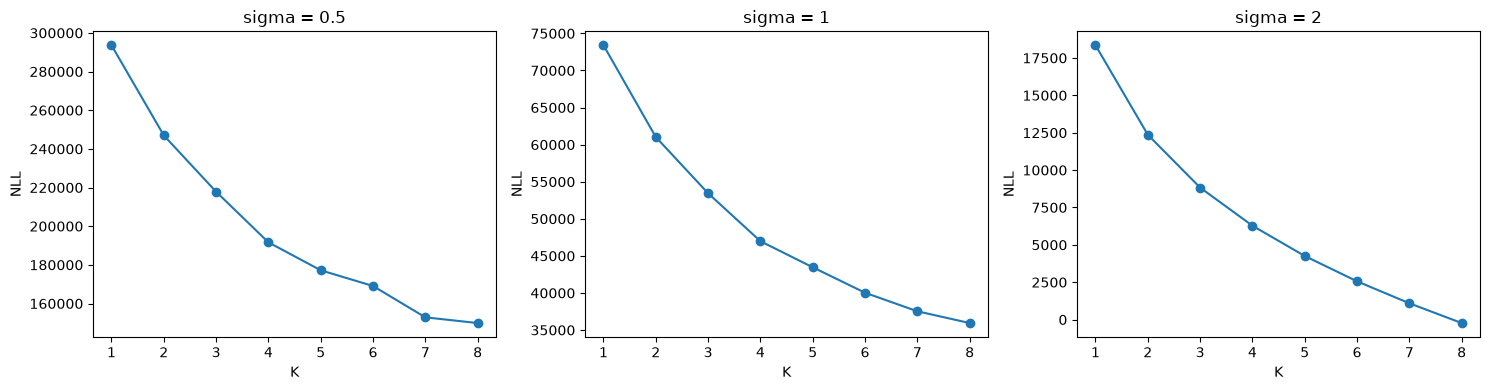

In [4]:
# (a) Optimal NLL vs number of clusters K for some values of sigma
sigmas = [0.5, 1, 2]
Ks = range(1, 9)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sigma in zip(axes, sigmas):
    nll = []
    for K in Ks:
        M, value = EM_clustering(X, sigma, K)
        nll.append(value[-1])
    ax.plot(Ks, nll, 'o-')
    ax.set_title('sigma = ' + str(sigma))
    ax.set_xlabel('K')
    ax.set_ylabel('NLL')
plt.tight_layout()
plt.show()

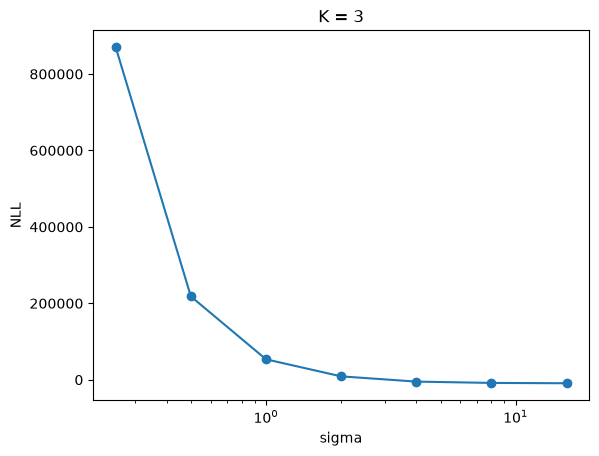

In [5]:
# (b) Optimal NLL vs sigma for K = 3
sigmas = [0.25, 0.5, 1, 2, 4, 8, 16]
nll = []
for sigma in sigmas:
    M, value = EM_clustering(X, sigma, 3)
    nll.append(value[-1])

plt.plot(sigmas, nll, 'o-')
plt.xscale('log')
plt.xlabel('sigma')
plt.ylabel('NLL')
plt.title('K = 3')
plt.show()

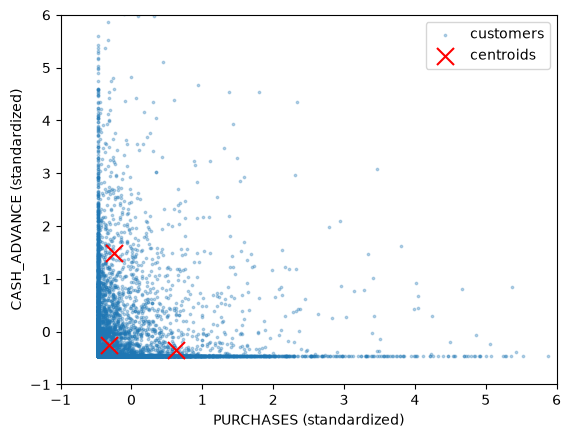

In [6]:
# (c) Scatter plot of two features with the trained centroids
f1 = 'PURCHASES'
f2 = 'CASH_ADVANCE'
j1 = df.columns.get_loc(f1)
j2 = df.columns.get_loc(f2)

M, value = EM_clustering(X, 1, 3)

plt.scatter(X[:, j1], X[:, j2], s=3, alpha=0.3, label='customers')
plt.scatter(M[:, j1], M[:, j2], c='red', marker='x', s=150, label='centroids')
plt.xlabel(f1 + ' (standardized)')
plt.ylabel(f2 + ' (standardized)')
plt.xlim(-1, 6)
plt.ylim(-1, 6)
plt.legend()
plt.show()

#### Report

We standardized all features before running EM since they have very different scales. Some are in the thousands and some are between 0 and 1.

**(a) Optimal NLL vs the number of clusters. Does it indicate a suitable number of clusters? Why?**

The NLL goes down every time we add a cluster, for all three values of $\sigma$. So the plot does not really indicate a suitable number of clusters. More centroids can always fit the data at least as well, and in the extreme case where $K = n$ every point would get its own centroid. That fits the data very well but is not a useful clustering. So the NLL alone can't be used to pick $K$, we would need something that also penalizes having many clusters or use what we know about the data.

**(b) Optimal NLL vs $\sigma$ for $K=3$. Explain the behavior.**

The NLL decreases when $\sigma$ increases. Every exponential term in the sum gets bigger when $\sigma$ grows, so the NLL as defined in (4) can only go down. For large $\sigma$ all terms are close to 1, the centroids end up close to the mean of the data and every point gets about the same weight 1/3 for each cluster. The NLL then gets close to $-n \log 3$ which is about $-9500$. This doesn't mean that a large $\sigma$ is better, because we dropped the constant $C$ which also depends on $\sigma$. If it was included the NLL would go up again for large $\sigma$.

**(c) 2D scatter plot of two features with the centroids.**

We used PURCHASES and CASH_ADVANCE with $K = 3$ and $\sigma = 1$. The three centroids roughly correspond to three types of customers. One group buys a lot, one buys little but uses more cash advance, and one has low activity in both. These groups could be targeted with different marketing. The plot only shows 2 of the 17 features, and some extreme customers are outside the axis limits.

## Q2.1 Projection operators

**(a) Projection onto the $\ell_2$ ball**

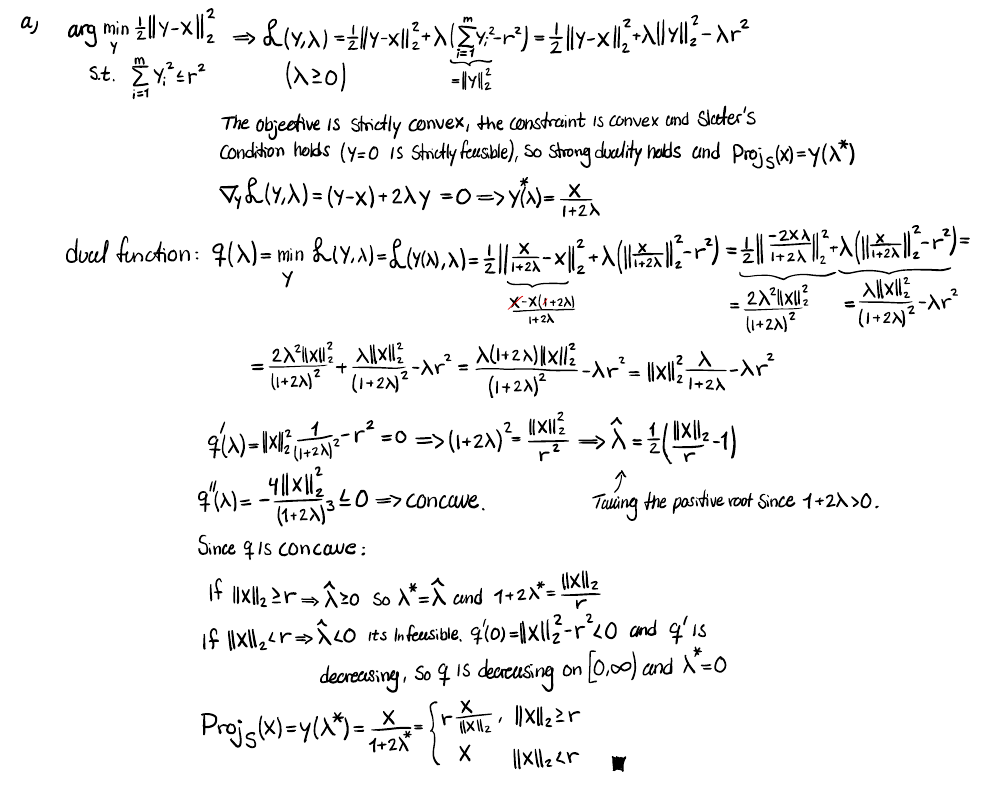

**(b) Shrinkage operator**

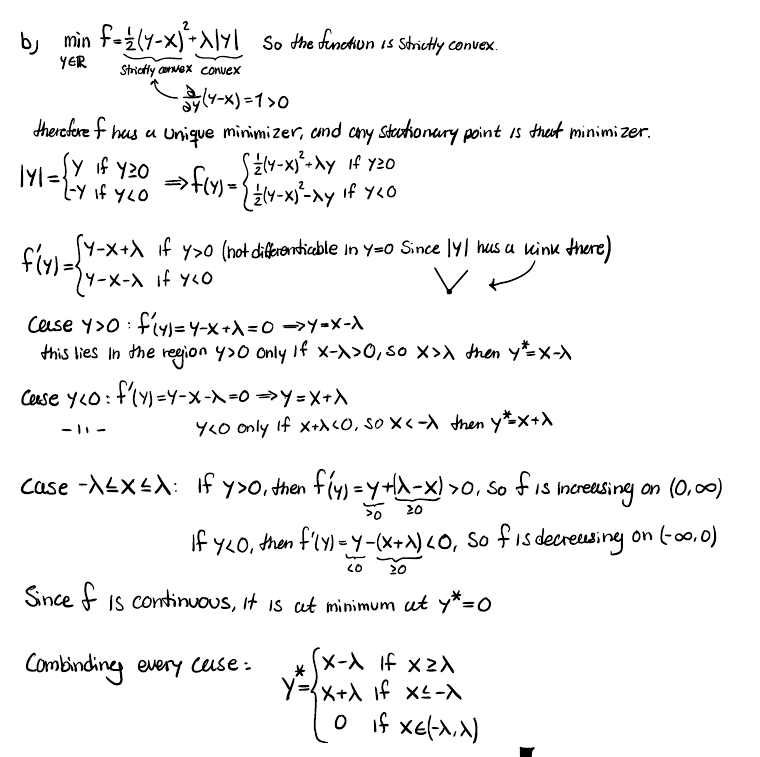

**(c) Projection onto the $\ell_1$ ball by dual gradient ascent**

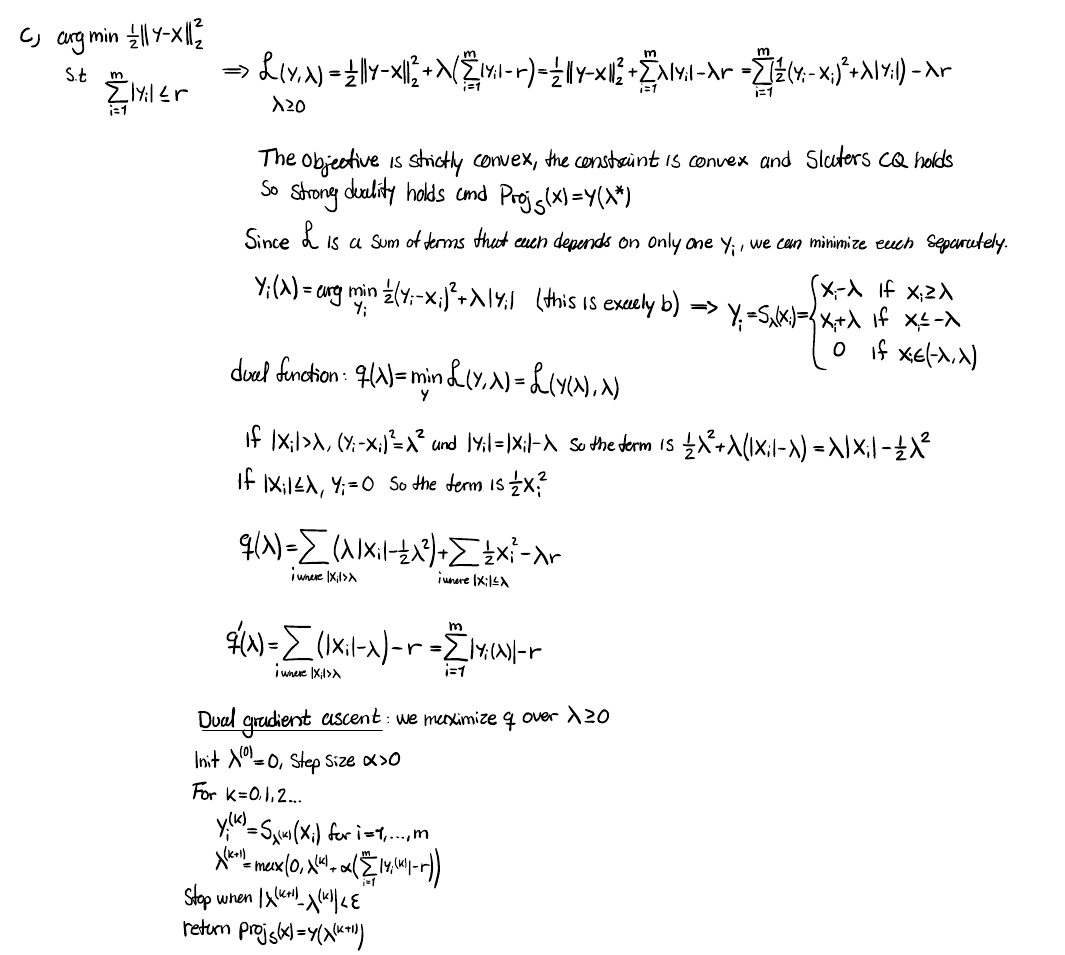

## Q2.2 Constrained least squares

In [7]:
npdata = np.loadtxt('Real estate.csv', delimiter=',', skiprows=1)
X_house = npdata[:, 1:7]
y_house = npdata[:, 7]
print(X_house.shape)

(414, 6)


In [8]:
def L1projection(x,r):
    #x is the point and r is the radius
    # Implement the dual gradient ascend algorithm with a suitable step size
    lam = 0.0
    alpha = 1 / len(x)
    eps = 1e-10
    
    for k in range(1000):
        y = np.zeros_like(x)
        for i in range(len(x)):
            if x[i] >= lam:
                y[i] = x[i] - lam
            elif x[i] <= -lam:
                y[i] = x[i] + lam
            elif -lam < x[i] < lam:
                y[i] = 0
                
        lam_next = max(0, lam + alpha * (np.sum(np.abs(y)) - r))
        if abs(lam_next - lam) < eps:
            break
        lam = lam_next

    return y

def L2projection(x,r):
    #x is the point and r is the radius
    # Implement by the closed form expression
    norm = np.linalg.norm(x)
    if norm >= r:
        return r * x / norm
    return x

def LINFprojection(x,r):
    #x is the point and r is the radius
    # Implement by the closed form expression
    y = np.zeros_like(x)

    for j in range(len(x)):
        if x[j] > r:
            y[j] = r
        elif x[j] < -r:
            y[j] = -r
        elif -r <= x[j] <= r:
            y[j] = x[j]

    return y

In [9]:
# Check your functions by projecting some random points and checking the result.
np.random.seed(0)
r = 1
x1 = np.array([3.0, 4.0])
x2 = np.array([0.2, -0.3])
x3 = np.random.randn(6) * 3

for x in [x1, x2, x3]:
    y1 = L1projection(x, r)
    y2 = L2projection(x, r)
    y3 = LINFprojection(x, r)
    print('x:', x)
    print('L1:', y1, 'norm:', np.sum(np.abs(y1)))
    print('L2:', y2, 'norm:', np.linalg.norm(y2))
    print('LINF:', y3, 'norm:', np.max(np.abs(y3)))
    print()

x: [3. 4.]
L1: [0. 1.] norm: 1.0
L2: [0.6 0.8] norm: 1.0
LINF: [1. 1.] norm: 1.0

x: [ 0.2 -0.3]
L1: [ 0.2 -0.3] norm: 0.5
L2: [ 0.2 -0.3] norm: 0.36055512754639896
LINF: [ 0.2 -0.3] norm: 0.3

x: [ 5.29215704  1.20047163  2.93621395  6.7226796   5.60267397 -2.93183364]
L1: [0. 0. 0. 1. 0. 0.] norm: 1.000000000596656
L2: [ 0.47669462  0.10813329  0.26448146  0.60554991  0.50466465 -0.2640869 ] norm: 0.9999999999999999
LINF: [ 1.  1.  1.  1.  1. -1.] norm: 1.0



In [14]:
# Implemnt PGD
# step size: step = 1/L
# number of iterations: T
# initialize theta ,mu

X_house = (X_house - X_house.mean(axis=0)) / X_house.std(axis=0)

def PGD(X, y, projection, r, step, T):
    # gradient step on theta and mu, then project theta
    # store the objective value in every iteration
    theta = np.zeros(X.shape[1])
    mu = 0
    values = np.zeros(T)
    
    for t in range(T):
        residual = y - X @ theta - mu
        grad_theta = -2 * X.T @ residual
        grad_mu = -2 * np.sum(residual)
        theta = theta - step * grad_theta
        mu = mu - step * grad_mu

        theta = projection(theta, r)
        values[t] = np.sum((y - X @ theta - mu) ** 2)

    return theta, mu, values

A = np.column_stack((X_house, np.ones(len(y_house))))
L = 2 * np.max(np.linalg.eigvalsh(A.T @ A))
step = 1 / L
T = 500
print(step)

0.0004515901960737591


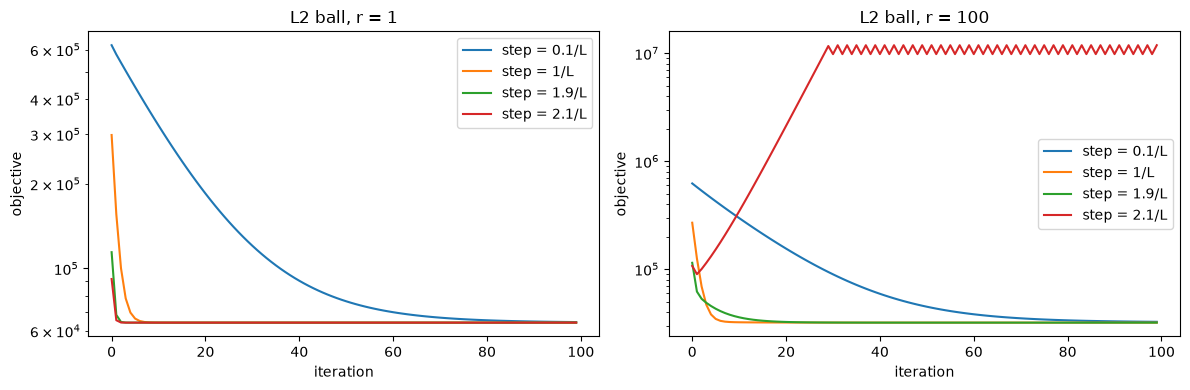

In [15]:
# (a) Effect of the step size with the L2 constraint
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, r in zip(axes, [1, 100]):
    for c in [0.1, 1, 1.9, 2.1]:
        theta, mu, values = PGD(X_house, y_house, L2projection, r, c * step, 100)
        ax.plot(values, label='step = ' + str(c) + '/L')
    ax.set_yscale('log')
    ax.set_title('L2 ball, r = ' + str(r))
    ax.set_xlabel('iteration')
    ax.set_ylabel('objective')
    ax.legend()
plt.tight_layout()
plt.show()

L1 69295.5104625368
L2 64196.722347202834
LINF 52201.41982174363


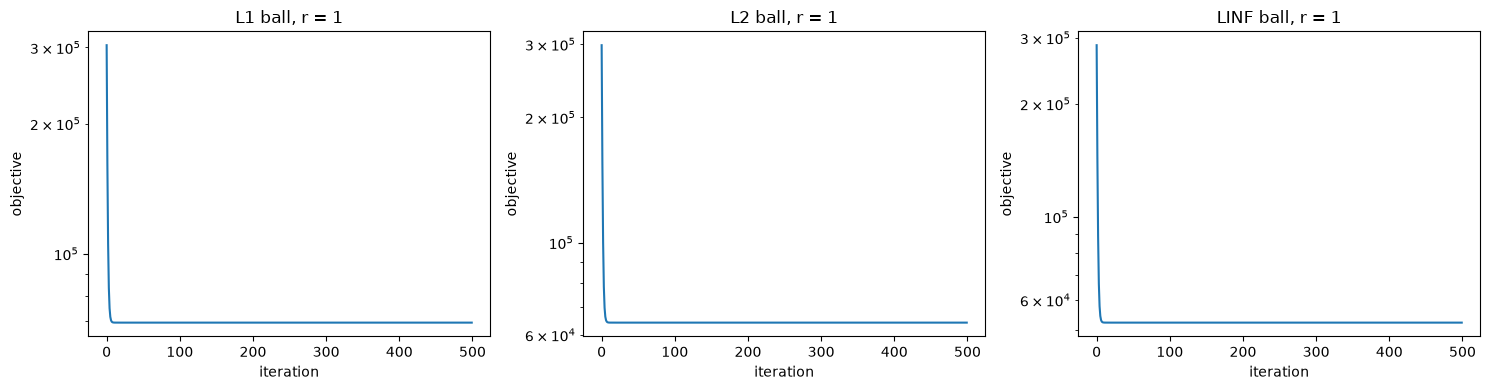

In [16]:
# (b) Objective value vs iterations for each constraint with r = 1
projections = [L1projection, L2projection, LINFprojection]
names = ['L1', 'L2', 'LINF']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, projection, name in zip(axes, projections, names):
    theta, mu, values = PGD(X_house, y_house, projection, 1, step, T)
    print(name, values[-1])
    ax.plot(values)
    ax.set_yscale('log')
    ax.set_title(name + ' ball, r = 1')
    ax.set_xlabel('iteration')
    ax.set_ylabel('objective')
plt.tight_layout()
plt.show()

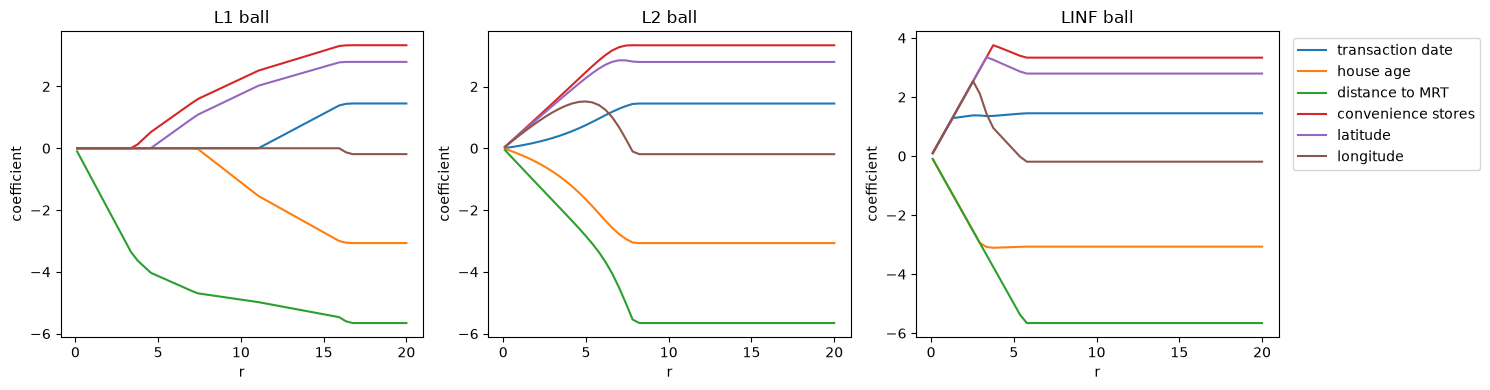

In [17]:
# (c) Trained coefficients vs the radius r for each constraint
radii = np.linspace(0.1, 20, 50)
features = ['transaction date', 'house age', 'distance to MRT', 'convenience stores', 'latitude', 'longitude']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, projection, name in zip(axes, projections, names):
    thetas = []
    for r in radii:
        theta, mu, values = PGD(X_house, y_house, projection, r, step, T)
        thetas.append(theta)
    ax.plot(radii, thetas)
    ax.set_title(name + ' ball')
    ax.set_xlabel('r')
    ax.set_ylabel('coefficient')
axes[2].legend(features, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Report

We standardized the features before running PGD. Without that the features have very different scales and the step size has to be extremely small.

**(a) Effect of the step size.**

We used the step size $1/L$ where $L$ is two times the largest eigenvalue of $A^TA$ and $A$ is $X$ with an extra column of ones. For our data this is about 0.00045. With a smaller step like $0.1/L$ the algorithm still converges but it needs a lot more iterations. Steps up to almost $2/L$ also converge. With $r = 100$ the constraint is not active and a step of $2.1/L$ makes the objective blow up and then jump back and forth. With $r = 1$ the same step does not diverge since the projection keeps $\theta$ inside a small ball, but in general a step larger than $2/L$ is not safe.

**(b) Objective value vs iterations for each constraint with $r=1$.**

With the step size $1/L$ all three versions converge in about 10 iterations. The final objective is about 69300 for the L1 ball, 64200 for the L2 ball and 52200 for the LINF ball. Without any constraint the least squares objective is about 31900, so the constraint is active in all three cases. The order makes sense because for the same $r$ the L1 ball is inside the L2 ball which is inside the LINF ball, and a bigger set gives a lower minimum. The intercept $\mu$ ends up at the mean house price 37.98 since the features are centered.

**(c) Trained coefficients vs the radius $r$.**

For large $r$ all three give the normal least squares solution since the constraint is not active anymore. This happens at about $r = 16.5$ for L1, $r = 7.9$ for L2 and $r = 5.7$ for LINF, which are the norms of the least squares solution. For the L1 ball the coefficients become nonzero one at a time. Distance to MRT comes first, then convenience stores, latitude, house age and transaction date, and longitude comes last. So the L1 constraint does a kind of feature selection. For the L2 ball all coefficients are nonzero for every $r$ and they grow smoothly. For the LINF ball most coefficients are equal to $r$ or $-r$ when $r$ is small, so the solution is in a corner of the box. As $r$ grows the coefficients leave the boundary one at a time. Since the features are correlated this does not happen exactly at their least squares values, for example convenience stores and latitude go above their least squares values before coming back. Longitude is positive for small $r$ with L2 and LINF even though its least squares value is close to zero and negative.

## Q3.1 Firmly nonexpansive

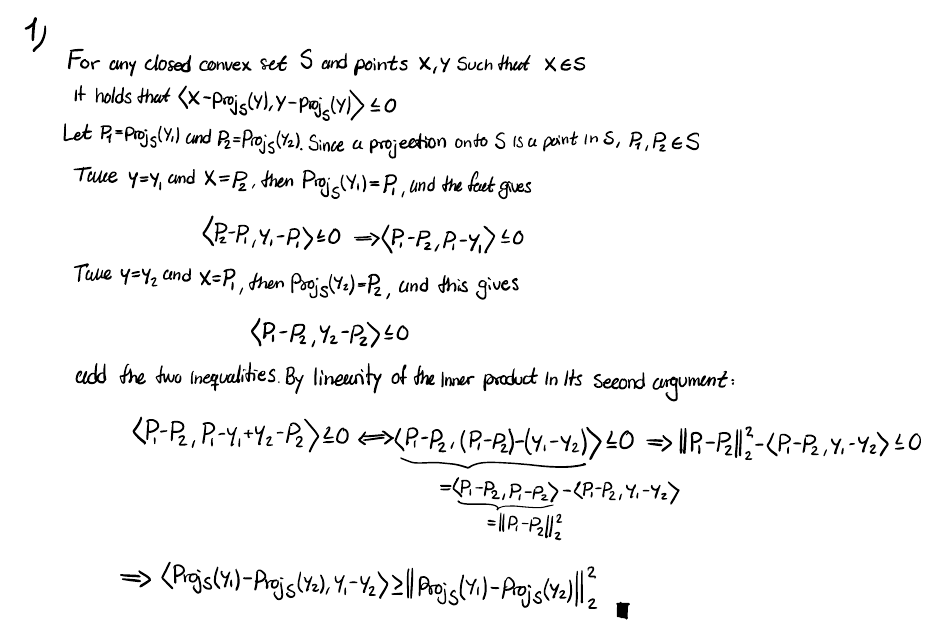

## Q3.2 Non-expansive

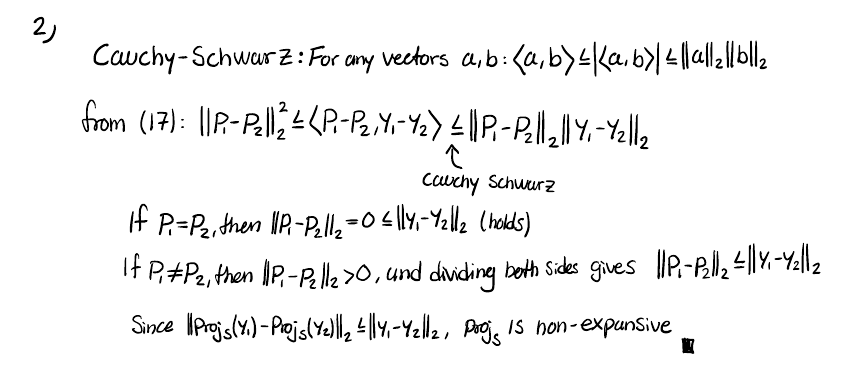